# 02 — Experiments and statistical analysis

Results of the five experiment designs in ODD section 8 (`experiments/designs.py`),
produced by `python -m experiments.run_experiments`. Each scenario runs with the
**same 30 seeds**, so for a given seed every scenario has the same households,
weather and outages (common random numbers). Results are reported as mean ± 95%
confidence interval; scenarios are compared with one-way ANOVA, Kruskal–Wallis
(robust to non-normality and unequal variances) and Tukey HSD, plus paired tests
on the seed-matched differences where two scenarios are compared directly.

Tariffs are still placeholders (import 0.20, export 0.05 EUR/kWh), so euro
values are indicative; relative comparisons are what matter at this stage.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "..")
from experiments.stats import compare, paired, replication_check, summary

RESULTS = Path("../experiments/results")
FIGS = Path("figures")
FIGS.mkdir(exist_ok=True)
pd.set_option("display.width", 200, "display.max_colwidth", 60)

e1, e2, e3, e4, e5 = (pd.read_csv(RESULTS / f"{n}.csv") for n in
                      ["e1_pricing", "e2_storage", "e3_demand_response", "e4_resilience", "e5_sensitivity"])

In [2]:
# Chart style (same as 01_data_check). Fixed colours per entity within each figure.
BLUE, ORANGE, AQUA, YELLOW, RED, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e34948", "#898781"
INK, INK2, GRID, AXIS = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": GRAY, "ytick.color": GRAY, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "legend.frameon": False, "legend.labelcolor": INK2,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "lines.linewidth": 1.6,
})

def dots(ax, x, s, kpi, labels, color, label, offset=0.0, scale=1.0, line=False):
    """Mean ± 95% CI for the given scenario labels."""
    m = s.loc[labels, (kpi, "mean")].astype(float) * scale
    h = s.loc[labels, (kpi, "ci95")].astype(float) * scale
    ax.errorbar(np.asarray(x) + offset, m, yerr=h, fmt="o-" if line else "o", color=color, label=label,
                ms=6, capsize=3, elinewidth=1.4, lw=1.6)

## Replication check

Is n = 30 enough? Largest relative 95% CI half-width (half-width / mean) of
each KPI over every scenario of every experiment.

In [3]:
everything = pd.concat([e1, e2, e3, e4, e5])
replication_check(everything, ["community_savings_eur", "self_sufficiency", "self_consumption",
                               "peak_import_kw", "gini_savings", "served_during_outages"]).round(3)

,max_rel_halfwidth,worst_scenario
community_savings_eur,0.041882,"frequent (12/yr, 1-8 h) | shared 100 | n=20"
self_sufficiency,0.033619,"base (4/yr, 1-8 h) | shared 100 | n=20"
self_consumption,0.040224,none | pv 20%
peak_import_kw,0.019474,"base (4/yr, 1-8 h) | individual 100 | n=20"
gini_savings,0.044089,sdr | pv 20%
served_during_outages,0.238624,fixed | pv 20%


With 30 seeds every energy and cost KPI is estimated within ±5% of its mean.
The exception is the **share of demand served during outages**: outages cover
only ~19 h per year, so this KPI is noisy (up to ±24%). For RQ4, either use
more seeds or report it mainly from the outage-heavy regimes of E4.

## E1 — Pricing mechanism × PV share (RQ1)

In [4]:
mechs = ["fixed", "mid_market", "sdr", "bill_sharing"]
mech_names = {"fixed": "fixed (0.10)", "mid_market": "mid-market", "sdr": "SDR", "bill_sharing": "bill-sharing"}
shares = [0.2, 0.4, 0.6, 0.8]
lab = lambda m, sh: f"{m} | pv {int(sh * 100)}%"
s1 = summary(e1, ["community_savings_eur", "self_sufficiency", "gini_savings",
                  "prosumer_savings_eur", "consumer_savings_eur"])
s1.round(3)

community_savings_eur          self_sufficiency        gini_savings        prosumer_savings_eur        consumer_savings_eur       
                                       mean     ci95             mean   ci95         mean   ci95                 mean   ci95                 mean   ci95
scenario                                                                                                                                                
none | pv 20%                        -0.000    0.000            0.082  0.002        0.000  0.000               -0.000  0.000                0.000  0.000
fixed | pv 20%                     3105.119  108.791            0.267  0.008        0.208  0.004              173.344  6.014               86.044  3.031
mid_market | pv 20%                3105.119  108.791            0.267  0.008        0.362  0.003              259.722  9.023               64.449  2.279
sdr | pv 20%                       3105.119  108.791            0.267  0.008        0.199  0.009               43.571  2.368              118.487  5.031
bill_sharing | pv 20%              3105.119  108.791            0.267  0.008        0.660  0.005             -172.168  6.030              172.422  6.040
none | pv 40%                         0.000    0.000            0.164  0.003        0.000  0.000                0.000  0.000                0.000  0.000
fixed | pv 40%                     3111.782   65.206            0.350  0.003        0.161  0.007               87.243  1.835              114.714  2.404
mid_market | pv 40%                3111.782   65.206            0.350  0.003        0.199  0.008              130.449  2.757               85.910  1.790
sdr | pv 40%                       3111.782   65.206            0.350  0.003        0.435  0.003                8.138  0.370              167.452  3.569
bill_sharing | pv 40%              3111.782   65.206            0.350  0.003        0.842  0.004              -85.580  1.868              229.930  4.864
none | pv 60%                         0.000    0.000            0.248  0.002        0.000  0.000                0.000  0.000                0.000  0.000
fixed | pv 60%                     2268.225   39.639            0.384  0.002        0.329  0.002               42.985  0.769              124.542  2.178
mid_market | pv 60%                2268.225   39.639            0.384  0.002        0.197  0.005               63.832  1.119               93.271  1.644
sdr | pv 60%                       2268.225   39.639            0.384  0.002        0.620  0.003                3.369  0.248              183.966  3.139
bill_sharing | pv 60%              2268.225   39.639            0.384  0.002        1.025  0.003              -40.404  0.708              249.625  4.320
none | pv 80%                         0.000    0.000            0.331  0.002        0.000  0.000                0.000  0.000                0.000  0.000
fixed | pv 80%                     1216.900   34.439            0.404  0.002        0.505  0.003               18.406  0.506              129.193  3.871
mid_market | pv 80%                1216.900   34.439            0.404  0.002        0.378  0.004               26.517  0.732               96.751  2.896
sdr | pv 80%                       1216.900   34.439            0.404  0.002        0.783  0.003                2.797  0.245              191.629  5.725
bill_sharing | pv 80%              1216.900   34.439            0.404  0.002        1.198  0.003              -14.037  0.575              258.963  7.774

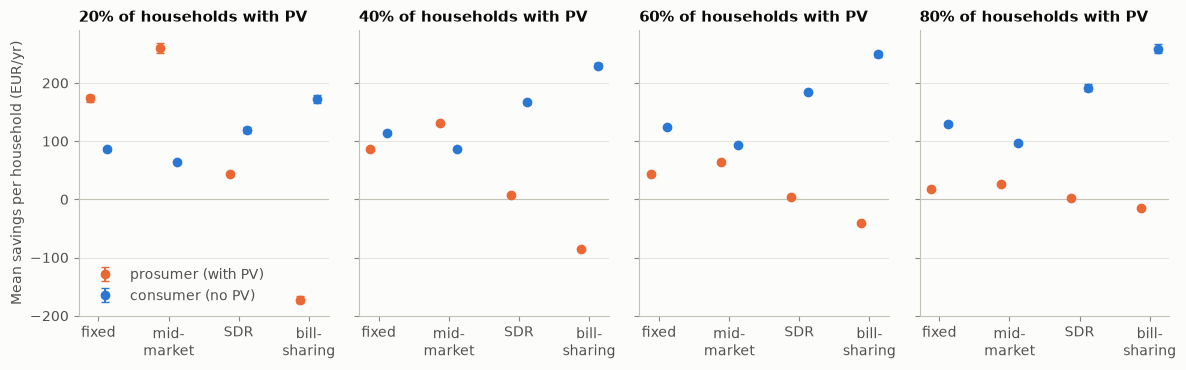

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.8), sharey=True)
x = np.arange(len(mechs))
for ax, sh in zip(axes, shares):
    labels = [lab(m, sh) for m in mechs]
    dots(ax, x, s1, "prosumer_savings_eur", labels, ORANGE, "prosumer (with PV)", -0.12)
    dots(ax, x, s1, "consumer_savings_eur", labels, BLUE, "consumer (no PV)", 0.12)
    ax.axhline(0, color=AXIS, lw=0.8)
    ax.set_xticks(x, ["fixed", "mid-\nmarket", "SDR", "bill-\nsharing"])
    ax.set_title(f"{int(sh * 100)}% of households with PV", loc="left")
axes[0].set_ylabel("Mean savings per household (EUR/yr)")
axes[0].legend(loc="lower left")
fig.tight_layout()
fig.savefig(FIGS / "e1_savings_by_group.png", dpi=150)

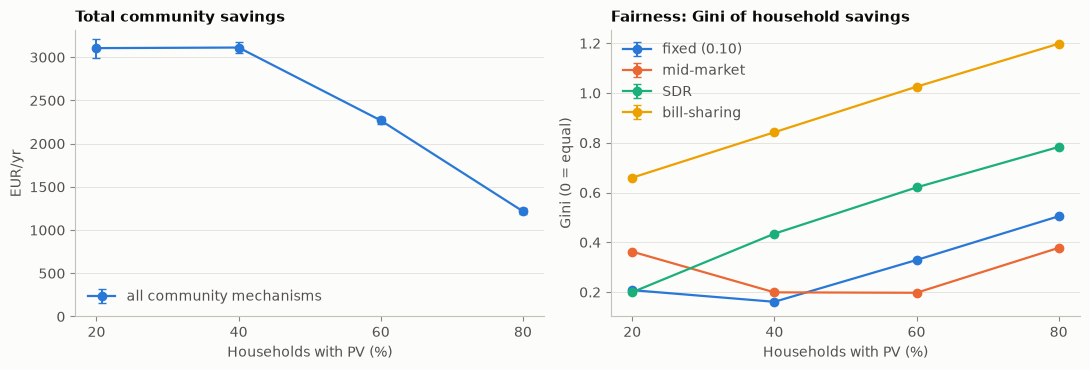

In [6]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.8))
pv_pct = [int(sh * 100) for sh in shares]
dots(a, pv_pct, s1, "community_savings_eur", [lab("mid_market", sh) for sh in shares], BLUE,
     "all community mechanisms", line=True)
a.set_title("Total community savings", loc="left")
a.set_ylabel("EUR/yr")
a.set_xlabel("Households with PV (%)")
a.set_ylim(bottom=0)
a.legend(loc="lower left")
for m, c in zip(mechs, [BLUE, ORANGE, AQUA, YELLOW]):
    dots(b, pv_pct, s1, "gini_savings", [lab(m, sh) for sh in shares], c, mech_names[m], line=True)
b.set_title("Fairness: Gini of household savings", loc="left")
b.set_ylabel("Gini (0 = equal)")
b.set_xlabel("Households with PV (%)")
b.legend(loc="upper left")
for ax in (a, b):
    ax.set_xticks(pv_pct)
fig.tight_layout()
fig.savefig(FIGS / "e1_total_and_gini.png", dpi=150)

In [7]:
# Tests at the baseline PV share (40%), community mechanisms only
e1_40 = e1[(e1["pv_share"] == 0.4) & (e1["pricing"] != "none")]
tests = []
for kpi in ["community_savings_eur", "gini_savings", "prosumer_savings_eur", "consumer_savings_eur"]:
    t, pairs = compare(e1_40, kpi)
    tests.append(t)
    if kpi == "gini_savings":
        gini_pairs = pairs
pd.concat(tests).round(4)

,min_shapiro_p,levene_p,anova_F,anova_p,kruskal_H,kruskal_p
kpi,,,,,,
community_savings_eur,0.2846,1.0000,0.0000,1.0,0.0040,0.9999
gini_savings,0.0984,0.0010,12392.8398,0.0,108.4953,0.0000
prosumer_savings_eur,0.1547,0.0000,10357.3789,0.0,111.5702,0.0000
consumer_savings_eur,0.2467,0.0002,1480.3365,0.0,111.5702,0.0000


In [8]:
gini_pairs.round(4)

,a,b,mean_diff,ci_low,ci_high,p_tukey
0,fixed | pv 40%,mid_market | pv 40%,-0.0380,-0.0484,-0.0276,0.0
1,fixed | pv 40%,sdr | pv 40%,-0.2737,-0.2840,-0.2633,0.0
2,fixed | pv 40%,bill_sharing | pv 40%,-0.6814,-0.6918,-0.6710,0.0
3,mid_market | pv 40%,sdr | pv 40%,-0.2357,-0.2460,-0.2253,0.0
4,mid_market | pv 40%,bill_sharing | pv 40%,-0.6434,-0.6538,-0.6330,0.0
5,sdr | pv 40%,bill_sharing | pv 40%,-0.4077,-0.4181,-0.3974,0.0


**Findings (E1)**

- **Total savings are identical for every mechanism** (ANOVA F = 0 at each PV
  share). Households do not react to prices in the current model, so the energy
  flows, and therefore the grid bill, do not depend on the price rule: every
  locally shared kWh saves p_imp − p_exp. The mechanism only decides **who gets
  the savings**. RQ1 should be reframed around the distribution of savings,
  unless some behaviour (cooperation, demand response, membership) is made
  price-responsive.
- **Distribution differs strongly** (all Tukey pairs p < 0.001 for the Gini
  coefficient). Mid-market splits the gain evenly per kWh between seller and
  buyer; SDR gives almost everything to consumers because local supply usually
  exceeds demand at midday, which sets the price to p_exp; under bill-sharing
  prosumers end up **worse off than alone** (negative savings, hence Gini > 1),
  which would make them leave a real community.
- **Total savings peak at 20–40% PV** and fall at 60–80%: with many prosumers
  there are too few consumers to absorb the midday surplus.

## E2 — Shared vs individual storage (RQ2)

In [9]:
s2 = summary(e2, ["community_savings_eur", "self_sufficiency", "self_consumption", "peak_import_kw",
                  "gini_savings", "prosumer_savings_eur", "consumer_savings_eur"])
s2.round(3)

community_savings_eur          self_sufficiency        self_consumption        peak_import_kw        gini_savings        prosumer_savings_eur         consumer_savings_eur       
                                    mean     ci95             mean   ci95             mean   ci95           mean   ci95         mean   ci95                 mean    ci95                 mean   ci95
scenario                                                                                                                                                                                            
none                            3111.782   65.206            0.350  0.003            0.626  0.013         26.777  0.404        0.199  0.008              130.449   2.757               85.910  1.790
individual 50 kWh               4003.624   61.114            0.408  0.005            0.753  0.013         26.284  0.387        0.420  0.006              251.701   2.997               54.623  1.575
shared 50 kWh                   4950.674   79.288            0.464  0.006            0.851  0.013         26.757  0.412        0.239  0.005              244.384   3.419              121.778  2.371
individual 100 kWh              4514.756   60.026            0.440  0.005            0.819  0.015         25.967  0.376        0.458  0.007              302.234   3.313               49.330  1.870
shared 100 kWh                  6029.675  147.455            0.531  0.011            0.982  0.006         26.703  0.411        0.262  0.005              314.640   8.380              140.467  3.474
individual 200 kWh              4620.528   63.030            0.446  0.006            0.832  0.015         25.600  0.371        0.467  0.007              313.829   3.738               47.476  1.838
shared 200 kWh                  6193.658  194.322            0.541  0.014            1.000  0.000         26.703  0.411        0.264  0.005              324.770  11.463              143.320  4.250

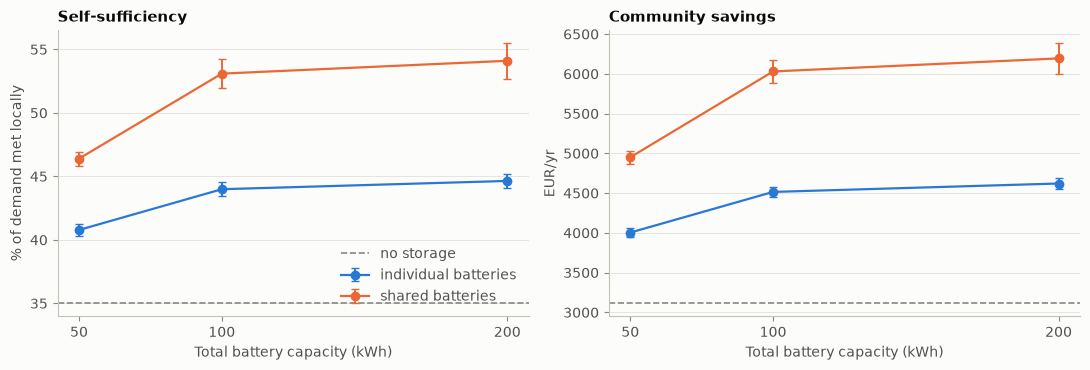

In [10]:
kwh = [50, 100, 200]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, kpi, scale, title, ylabel in [
    (axes[0], "self_sufficiency", 100, "Self-sufficiency", "% of demand met locally"),
    (axes[1], "community_savings_eur", 1, "Community savings", "EUR/yr"),
]:
    for mode, c in [("individual", BLUE), ("shared", ORANGE)]:
        dots(ax, kwh, s2, kpi, [f"{mode} {k} kWh" for k in kwh], c, f"{mode} batteries", scale=scale, line=True)
    ax.axhline(s2.loc["none", (kpi, "mean")] * scale, color=GRAY, ls="--", lw=1.2, label="no storage")
    ax.set_title(title, loc="left")
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Total battery capacity (kWh)")
    ax.set_xticks(kwh)
axes[0].legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIGS / "e2_storage.png", dpi=150)

In [11]:
t, _ = compare(e2, "self_sufficiency")
display(t.round(4))
pd.DataFrame([paired(e2, kpi, f"shared {k} kWh", f"individual {k} kWh")
              for kpi in ["community_savings_eur", "self_sufficiency"] for k in kwh]).round(4)

,min_shapiro_p,levene_p,anova_F,anova_p,kruskal_H,kruskal_p
kpi,,,,,,
self_sufficiency,0.1725,0.0,295.5558,0.0,186.9869,0.0


,a,b,kpi,mean_diff,ci_low,ci_high,p_paired_t,p_wilcoxon
0,shared 50 kWh,individual 50 kWh,community_savings_eur,947.0497,927.2171,966.8823,0.0,0.0
1,shared 100 kWh,individual 100 kWh,community_savings_eur,1514.9190,1413.3356,1616.5024,0.0,0.0
2,shared 200 kWh,individual 200 kWh,community_savings_eur,1573.1303,1423.9580,1722.3027,0.0,0.0
3,shared 50 kWh,individual 50 kWh,self_sufficiency,0.0562,0.0547,0.0576,0.0,0.0
4,shared 100 kWh,individual 100 kWh,self_sufficiency,0.0910,0.0842,0.0979,0.0,0.0
5,shared 200 kWh,individual 200 kWh,self_sufficiency,0.0946,0.0848,0.1044,0.0,0.0


**Findings (E2)**

- **The shared battery beats the same capacity split into home batteries** at
  every size, in both self-sufficiency and savings (paired differences, all
  p < 0.001; e.g. +1,515 EUR/yr and +9 percentage points of self-sufficiency at
  100 kWh). A shared battery can store any member's surplus and serve any
  member's deficit; a home battery only serves its own house.
- **Diminishing returns**: going from 100 to 200 kWh adds little, because the
  community's daily surplus rarely fills more than ~100 kWh.
- Home batteries concentrate the gain on prosumers (consumers' savings fall,
  Gini ~0.46); the shared battery spreads it (Gini ~0.26).

## E3 — Demand response (RQ3)

community_savings_eur         self_sufficiency        peak_import_kw        gini_savings       
                          mean    ci95             mean   ci95           mean   ci95         mean   ci95
scenario                                                                                                
flex 0.0              3111.782  65.206            0.350  0.003         26.777  0.404        0.199  0.008
flex 0.1              3988.754  72.739            0.402  0.003         28.122  0.456        0.225  0.005
flex 0.2              4639.344  83.719            0.441  0.005         41.538  0.622        0.250  0.005

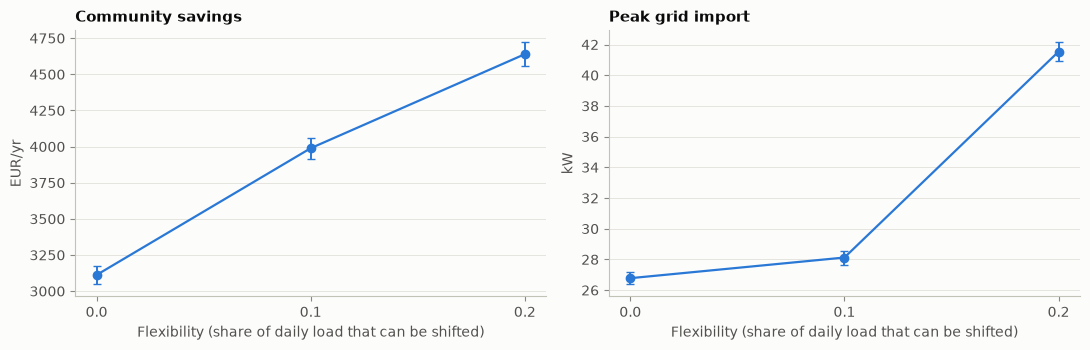

In [12]:
s3 = summary(e3, ["community_savings_eur", "self_sufficiency", "peak_import_kw", "gini_savings"])
display(s3.round(3))

flex = [0.0, 0.1, 0.2]
labels = [f"flex {f}" for f in flex]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
dots(axes[0], flex, s3, "community_savings_eur", labels, BLUE, None, line=True)
axes[0].set_title("Community savings", loc="left")
axes[0].set_ylabel("EUR/yr")
dots(axes[1], flex, s3, "peak_import_kw", labels, BLUE, None, line=True)
axes[1].set_title("Peak grid import", loc="left")
axes[1].set_ylabel("kW")
for ax in axes:
    ax.set_xlabel("Flexibility (share of daily load that can be shifted)")
    ax.set_xticks(flex)
fig.tight_layout()
fig.savefig(FIGS / "e3_demand_response.png", dpi=150)

In [13]:
pd.concat([compare(e3, k)[0] for k in ["community_savings_eur", "self_sufficiency", "peak_import_kw"]]).round(4)

,min_shapiro_p,levene_p,anova_F,anova_p,kruskal_H,kruskal_p
kpi,,,,,,
community_savings_eur,0.2846,0.6260,445.5240,0.0,78.1657,0.0
self_sufficiency,0.3614,0.0345,664.1129,0.0,78.5103,0.0
peak_import_kw,0.2234,0.1873,1102.5505,0.0,66.4089,0.0


**Findings (E3)**

- Demand response **adds savings on top of sharing** (+877 EUR/yr at 0.1,
  +1,528 EUR/yr at 0.2; Tukey p < 0.001).
- But it **raises the peak grid import** from ~27 kW to ~42 kW at 0.2. All
  households shift load at the same time based on the same forecast
  ("tomorrow = today"); on a cloudy day after a sunny one, that shifted load
  is imported. A rebound peak caused by synchronised flexibility is a known
  real-world effect and an emergent result of the model.

## E4 — Resilience to outages (RQ4)

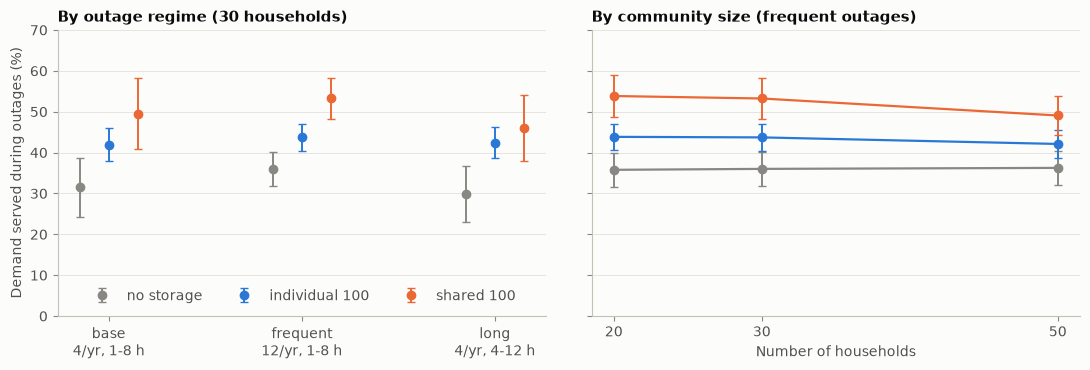

In [14]:
s4 = summary(e4, ["served_during_outages", "lost_load_kwh", "lost_load_alone_kwh", "outage_hours"])
regimes = ["base (4/yr, 1-8 h)", "frequent (12/yr, 1-8 h)", "long (4/yr, 4-12 h)"]
storage_opts = [("no storage", GRAY), ("individual 100", BLUE), ("shared 100", ORANGE)]
lab4 = lambda r, s, n: f"{r} | {s} | n={n}"

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
x = np.arange(len(regimes))
for (st, c), off in zip(storage_opts, [-0.15, 0, 0.15]):
    dots(axes[0], x, s4, "served_during_outages", [lab4(r, st, 30) for r in regimes], c, st, off, scale=100)
axes[0].set_xticks(x, ["base\n4/yr, 1-8 h", "frequent\n12/yr, 1-8 h", "long\n4/yr, 4-12 h"])
axes[0].set_title("By outage regime (30 households)", loc="left")
axes[0].set_ylabel("Demand served during outages (%)")
axes[0].legend(loc="lower center", ncol=3)
sizes = [20, 30, 50]
for st, c in storage_opts:
    dots(axes[1], sizes, s4, "served_during_outages", [lab4("frequent (12/yr, 1-8 h)", st, n) for n in sizes],
         c, st, scale=100, line=True)
axes[1].set_xticks(sizes)
axes[1].set_xlabel("Number of households")
axes[1].set_title("By community size (frequent outages)", loc="left")
axes[0].set_ylim(0, 70)
fig.tight_layout()
fig.savefig(FIGS / "e4_resilience.png", dpi=150)

In [15]:
pd.concat([compare(e4[e4["scenario"].isin([lab4(r, st, 30) for st, _ in storage_opts])], "served_during_outages")[0]
           .rename(index={"served_during_outages": r}) for r in regimes]).round(4)

,min_shapiro_p,levene_p,anova_F,anova_p,kruskal_H,kruskal_p
kpi,,,,,,
"base (4/yr, 1-8 h)",0.2627,0.0017,7.1687,0.0013,12.0815,0.0024
"frequent (12/yr, 1-8 h)",0.6148,0.2316,17.3467,0.0000,24.1701,0.0000
"long (4/yr, 4-12 h)",0.0665,0.0006,7.2232,0.0013,10.2285,0.0060


In [16]:
pd.DataFrame([paired(e4, "served_during_outages", lab4(r, "shared 100", 30), lab4(r, b, 30))
              for r in regimes for b in ["no storage", "individual 100"]]).round(4)

,a,b,kpi,mean_diff,ci_low,ci_high,p_paired_t,p_wilcoxon
0,"base (4/yr, 1-8 h) | shared 100 | n=30","base (4/yr, 1-8 h) | no storage | n=30",served_during_outages,0.1805,0.1249,0.2362,0.0000,0.0000
1,"base (4/yr, 1-8 h) | shared 100 | n=30","base (4/yr, 1-8 h) | individual 100 | n=30",served_during_outages,0.0764,0.0166,0.1362,0.0141,0.0120
2,"frequent (12/yr, 1-8 h) | shared 100 | n=30","frequent (12/yr, 1-8 h) | no storage | n=30",served_during_outages,0.1722,0.1393,0.2051,0.0000,0.0000
3,"frequent (12/yr, 1-8 h) | shared 100 | n=30","frequent (12/yr, 1-8 h) | individual 100 | n=30",served_during_outages,0.0952,0.0691,0.1212,0.0000,0.0000
4,"long (4/yr, 4-12 h) | shared 100 | n=30","long (4/yr, 4-12 h) | no storage | n=30",served_during_outages,0.1612,0.1170,0.2054,0.0000,0.0000
5,"long (4/yr, 4-12 h) | shared 100 | n=30","long (4/yr, 4-12 h) | individual 100 | n=30",served_during_outages,0.0357,-0.0194,0.0907,0.1955,0.1909


**Findings (E4)**

- Even **without storage**, the community serves ~30–36% of demand during
  outages (midday outages are covered by PV), and its lost load is ~20–25%
  lower than the same households alone, because prosumers' surplus reaches
  their neighbours.
- A **100 kWh shared battery** raises the served share to ~46–54%; individual
  batteries to ~42–44%. Shared beats no storage in every regime (paired
  p < 0.001). Shared beats individual with frequent outages (+9.5 pp,
  p < 0.001) and base outages (+7.6 pp, p = 0.014), but **not with long
  outages** (+3.6 pp, p = 0.20): over 4–12 h both kinds of battery run empty.
  The unpaired Tukey test is less conclusive, because the outage KPI is noisy
  (see the replication check).
- With a fixed 100 kWh, the served share **drops for 50 households** (less
  storage per house).
- The battery has **no outage reserve**: it is often empty when a night
  outage starts. A minimum state-of-charge reserve is a natural policy lever
  for RQ4.

## E5 — One-at-a-time sensitivity

Baseline: mid-market pricing, 100 kWh shared battery. Change in community
savings relative to the baseline (paired by seed).

,b,kpi,mean_diff,ci_low,ci_high,p_paired_t,p_wilcoxon,mean_diff_pct,ci_low_pct,ci_high_pct
a,,,,,,,,,,
cooperation 0.5,baseline,community_savings_eur,-2808.0780,-2861.1322,-2755.0238,0.0,0.0,-46.5710,-47.4508,-45.6911
cooperation 0.75,baseline,community_savings_eur,-1313.0183,-1337.4824,-1288.5543,0.0,0.0,-21.7759,-22.1817,-21.3702
efficiency 0.8,baseline,community_savings_eur,-399.7601,-407.7891,-391.7310,0.0,0.0,-6.6299,-6.7630,-6.4967
efficiency 0.95,baseline,community_savings_eur,190.5613,187.5785,193.5441,0.0,0.0,3.1604,3.1109,3.2099
export price 0.03,baseline,community_savings_eur,862.6420,841.0801,884.2039,0.0,0.0,14.3066,13.9490,14.6642
export price 0.08,baseline,community_savings_eur,-1293.9630,-1326.3059,-1261.6201,0.0,0.0,-21.4599,-21.9963,-20.9235


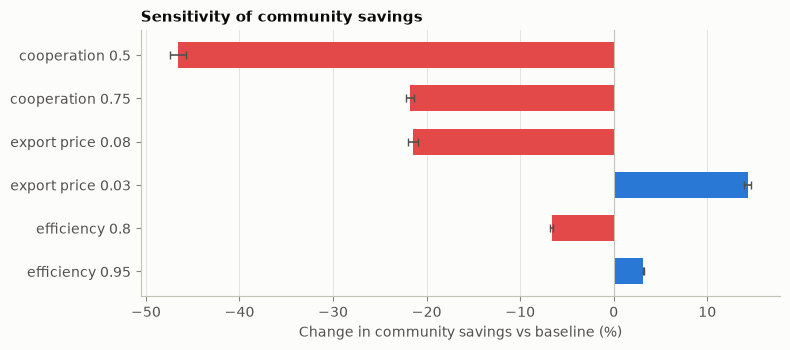

In [17]:
rows = [paired(e5, "community_savings_eur", sc, "baseline") for sc in e5["scenario"].unique() if sc != "baseline"]
sens = pd.DataFrame(rows).set_index("a")
base_mean = e5.loc[e5["scenario"] == "baseline", "community_savings_eur"].mean()
for c in ["mean_diff", "ci_low", "ci_high"]:
    sens[c + "_pct"] = 100 * sens[c] / base_mean
display(sens.round(4))

order = sens["mean_diff_pct"].abs().sort_values().index
fig, ax = plt.subplots(figsize=(8, 3.6))
vals = sens.loc[order, "mean_diff_pct"]
err = [vals - sens.loc[order, "ci_low_pct"], sens.loc[order, "ci_high_pct"] - vals]
ax.barh(order, vals, xerr=err, color=[BLUE if v > 0 else RED for v in vals], height=0.6,
        error_kw={"elinewidth": 1.2, "capsize": 3, "ecolor": INK2})
ax.axvline(0, color=AXIS, lw=0.8)
ax.set_axisbelow(True)
ax.grid(axis="x", color=GRID, lw=0.6)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Change in community savings vs baseline (%)")
ax.set_title("Sensitivity of community savings", loc="left")
fig.tight_layout()
fig.savefig(FIGS / "e5_sensitivity.png", dpi=150)

**Findings (E5)**

- **Cooperation is the most influential parameter**: if each prosumer offers
  its surplus only half of the time, savings fall by about half.
- A **lower export price raises the value of sharing** (+14% at 0.03 EUR/kWh,
  −21% at 0.08): local trading is worth exactly the gap between import and
  export prices, so the final tariff choice matters for the euro results.
- Battery efficiency matters little within 80–95% (−7% to +3%).